# 15 — Network history, converted-channel audit and StationXML

Run **after step 10**. This notebook separates three things: documented equipment/deployment history, channel identities actually present in the converted waveform archive, and a response model. None is a substitute for the other.

**Purpose:** refresh header evidence from the exact configured output archive; reconstruct the documentary network; expose metadata conflicts; create traceable draft StationXML; audit epoch selection and response completeness. Existing step 05 remains useful for an early documentary overview. Step 15 is the post-conversion review and packaging step.

**What running this notebook does:** reads waveform headers and historical reference files; writes tables, maps, diagrams, XML and provenance beneath `conversion_config.json`'s `output_root/network_history`. It does not edit legacy inputs, change waveform samples, correct clocks or relocate stations. Full archive header scanning can take several minutes. It replaces generated network-history outputs in that directory; preserve an earlier run externally if needed.

**Scientific status:** provisional metadata. Schema-valid XML is not proof of correct instruments, calibration or timing. A complete counts-to-ground-motion response remains an explicit target; missing electronics must not be replaced with invented unity stages.


## 1. Load the shared configuration and display the actual paths

This block locates `10_conversion` from either the repository root or notebook folder, imports the pipeline path resolver, and identifies both the configured **converted WAV database** and external output directory. It deliberately does not reconstruct a waveform path from `DATA_TOP/FAIR`: that would select the older assembled archive rather than the current conversion run. Restart the kernel after updating local modules.


In [1]:
from pathlib import Path
import sys,json,hashlib,shutil
from datetime import datetime,timezone
from IPython.display import display,Image,Markdown
import pandas as pd
from obspy import read_inventory,UTCDateTime
candidates=[Path.cwd(),Path.cwd()/'10_conversion',*Path.cwd().parents]
PIPELINE=next((p for p in candidates if (p/'pinatubo_steps').is_dir() and (p/'network_history').is_dir()),None)
if PIPELINE is None:raise FileNotFoundError('Open from the project root or 10_conversion folder')
sys.path.insert(0,str(PIPELINE.resolve()))
from pinatubo_steps.config import pipeline_paths
from network_history.reconstruct import build_all,DATA
from network_history.finalize_inventory import scan_converted_headers,audit_inventory,exclusive_boundary_copy,package_evidence,sha256
CONFIG_FILE=None
P=pipeline_paths(config_file=CONFIG_FILE)
WAV_ROOT=Path(P['SEISAN_WAV_DB'])
OUTPUT=Path(P['NETWORK_HISTORY_OUTPUT'])
HEADER_OUTPUT=OUTPUT/'header_scan'
print('Configuration:',P['CONFIG_FILE'])
print('Converted waveforms:',WAV_ROOT)
print('Generated network metadata:',OUTPUT)
if not WAV_ROOT.is_dir():raise FileNotFoundError('Run step 10 first or check conversion_config.json: '+str(WAV_ROOT))


Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
Converted waveforms: /Users/thompsong/work/Pinatubo1991Processing/converted/FAIR/SEISAN/WAV/PNTBO
Generated network metadata: /Users/thompsong/work/Pinatubo1991Processing/converted/network_history


## 2. Refresh observed channel identity and coverage

Read the converted files' headers for the selected years. Default `YEARS=(1991,)` covers the conversion study; extend explicitly for additional years. Each daily row is grouped by directory month, recorded date and SEED ID. A header proves a saved identity, not valid signal, successful installation or continuous uptime. Header-only reading does not detect dead channels or clipping. Recorded timestamps remain uncorrected.

The scan saves its exact source root, per-file path/size/modification-time inventory, failures and daily identity table. `HASH_WAVEFORMS=True` additionally reads and hashes every waveform's bytes (slower); otherwise the file manifest is a structural inventory, not proof of byte identity. Generated metadata and code are hashed later regardless.

**Safe cache reuse:** when `RUN_HEADER_SCAN=False`, the following block checks the recorded root, selected years and every listed file's size/mtime, and checks for newly added or missing files. It refuses stale evidence instead of silently falling back to the bundled historical scan. Historical first/last bounds must be rerun after changes to step 10.


In [2]:
YEARS=(1991,)
RUN_HEADER_SCAN=True
HASH_WAVEFORMS=False
if RUN_HEADER_SCAN:
    headers=scan_converted_headers(WAV_ROOT,HEADER_OUTPUT,years=YEARS,hash_waveforms=HASH_WAVEFORMS)
else:
    summary=json.loads((HEADER_OUTPUT/'header_scan_summary.json').read_text())
    if Path(summary['source_root']).resolve()!=WAV_ROOT.resolve() or summary['years']!=list(YEARS):
        raise ValueError('Cached scan describes a different archive/year selection; rescan')
    previous=json.loads((HEADER_OUTPUT/'waveform_file_manifest.json').read_text())
    current={str(p.resolve()):p for year in YEARS for p in (WAV_ROOT/str(year)).rglob('*') if p.is_file() and not p.name.startswith('.')}
    if set(current)!={str(Path(r['path']).resolve()) for r in previous}:raise ValueError('Archive membership changed; rescan')
    for r in previous:
        f=current[str(Path(r['path']).resolve())];st=f.stat()
        if st.st_size!=r['bytes'] or st.st_mtime_ns!=r['mtime_ns']:raise ValueError('Archive file changed; rescan: '+str(f))
        if r.get('sha256') and sha256(f)!=r['sha256']:raise ValueError('Waveform hash changed; rescan')
    headers=pd.read_csv(HEADER_OUTPUT/'waveform_header_presence.csv',dtype={'file_month':str})
display(pd.DataFrame([json.loads((HEADER_OUTPUT/'header_scan_summary.json').read_text())]))
display(headers.head(20))
display(pd.read_csv(HEADER_OUTPUT/'header_scan_failures.csv'))


Headers inspected: 1000/21449
Headers inspected: 2000/21449
Headers inspected: 3000/21449
Headers inspected: 4000/21449
Headers inspected: 5000/21449
Headers inspected: 6000/21449
Headers inspected: 7000/21449
Headers inspected: 8000/21449
Headers inspected: 9000/21449
Headers inspected: 10000/21449
Headers inspected: 11000/21449
Headers inspected: 12000/21449
Headers inspected: 13000/21449
Headers inspected: 14000/21449
Headers inspected: 15000/21449
Headers inspected: 16000/21449
Headers inspected: 17000/21449
Headers inspected: 18000/21449
Headers inspected: 19000/21449
Headers inspected: 20000/21449
Headers inspected: 21000/21449


,source_root,years,files_read,failures,waveform_content_hashing,identity_only
0,/Users/thompsong/work/Pinatubo1991Processing/c...,[1991],21449,0,False,True


,file_month,date,network,station,location,channel,files,first,last,sample_rates,example_file
2,05,1991-05-01,XB,CAB,,EHZ,22,1991-05-01T10:45:26.647000Z,1991-05-01T21:22:26.481000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
0,05,1991-05-01,XB,PIE,,EHZ,24,1991-05-01T03:10:09.950000Z,1991-05-01T21:22:26.481000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
1,05,1991-05-01,XB,UBO,,EHZ,24,1991-05-01T03:10:09.950000Z,1991-05-01T21:22:26.481000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
3,05,1991-05-02,XB,CAB,,EHZ,6,1991-05-02T16:41:13.763000Z,1991-05-02T23:00:31.557000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
4,05,1991-05-02,XB,PIE,,EHZ,6,1991-05-02T16:41:13.763000Z,1991-05-02T23:00:31.557000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
5,05,1991-05-02,XB,UBO,,EHZ,6,1991-05-02T16:41:13.763000Z,1991-05-02T23:00:31.557000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
6,05,1991-05-03,XB,CAB,,EHZ,32,1991-05-03T00:08:49.333000Z,1991-05-03T23:59:35.070000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
7,05,1991-05-03,XB,PIE,,EHZ,32,1991-05-03T00:08:49.333000Z,1991-05-03T23:59:35.070000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
8,05,1991-05-03,XB,UBO,,EHZ,32,1991-05-03T00:08:49.333000Z,1991-05-03T23:59:35.070000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
9,05,1991-05-04,XB,CAB,,EHZ,74,1991-05-04T00:26:34.912000Z,1991-05-04T23:50:57.029000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...


,path,error


## 3. Construct the documentary reconstruction using the refreshed evidence

`build_all` writes history, coordinates, epoch tables, maps and two response variants. Passing `header_data_dir` explicitly makes this run use the scan above. Field-note dates are not silently replaced by waveform timestamps. Current post-eruption inference is still provisional and historically focused on June–August; the full-year scan supports additional inspection without claiming that every channel's deployment history has been solved.

Outputs include `pinatubo_provisional.xml` (identity/location/epoch metadata, no end-to-end responses) and `pinatubo_nominal_voltage_models.xml` (nominal sensor/attenuation models with **V**, not counts, as output). Do not run `remove_response` on digital counts using the latter as if it were the complete acquisition response.


In [3]:
report=build_all(OUTPUT,header_data_dir=HEADER_OUTPUT)
display(report)
stations=pd.read_csv(OUTPUT/'pinatubo_stations.csv')
epochs=pd.read_csv(OUTPUT/'pinatubo_channel_epochs.csv')
display(stations)
display(epochs)
display(Markdown((OUTPUT/'chronology.md').read_text()))


{'stations': 13,
 'channel_epochs': 26,
 'full_count_responses': 0,
 'status': 'DRAFT: unknown electronics, undated PI2 low-gain channel, approximate epoch bounds and provisional modern DEM LIL elevation explicit'}

,code,name,latitude,longitude,elevation_m,coordinate_source
0,CAB,Clark Air Base,15.189833,120.505833,220.0,Published pre-eruption Table 1 supplied by Wen...
1,PIE,Mount Pinatubo East,15.166667,120.429167,880.0,Published pre-eruption Table 1 supplied by Wen...
2,UBO,Geothermal drill pad,15.139167,120.362500,1200.0,Published pre-eruption Table 1 supplied by Wen...
3,PPO,Patal Pinto,15.182500,120.341667,840.0,Published pre-eruption Table 1 supplied by Wen...
4,BUR,Burgos,15.222833,120.256833,380.0,Published pre-eruption Table 1 supplied by Wen...
5,GRN,Mount Negron,15.095000,120.366667,1560.0,Published pre-eruption Table 1 supplied by Wen...
6,BUG,Sitio Buag,15.084000,120.281667,600.0,Published pre-eruption Table 1 supplied by Wen...
7,DON,DON (site name unverified),15.378333,120.503333,100.0,STATIONS.INP coordinates; PIN_STA_ALL elevatio...
8,CRW,Crow's Nest (code/location correspondence prov...,15.279333,120.349500,668.0,STATIONS.INP coordinates; PIN_STA_ALL elevatio...
9,PI2,PI2 (site name unverified),15.220833,120.417667,720.0,STATIONS.INP coordinates; PIN_STA_ALL elevatio...


,station,channel,start,end,sensor,attenuation_db,depth_m,sample_rate_hz,note
0,LIL,EHZ,1991-04-25,1991-05-01,L4-C,30.0,1.0,100.000000,Date-only boundaries use nominal UTC midnight;...
1,PIE,EHZ,1991-04-30,1991-06-16,L4-C,18.0,1.0,100.000000,Destroyed June 15; end June 16 is an inclusive...
2,UBO,EHZ,1991-05-01,1991-06-11T14:00:00,L4-C,36.0,0.0,100.000000,"Buried in rocky fill, exact depth unknown: 0 m..."
3,BUR,EHZ,1991-05-05,1991-06-12,L4-C,24.0,1.0,100.000000,Link lost June 11; end is inclusive-day conven...
4,PPO,EHZ,1991-05-03,1991-05-12,L4-C,36.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
5,PPO,EHZ,1991-05-12,1991-05-30,L22-D,24.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
6,PPO,EHZ,1991-05-30,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
7,PPO,EHN,1991-05-12,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
8,PPO,EHE,1991-05-12,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
9,BUG,EHZ,1991-05-11,1991-06-16,L4-C,18.0,1.0,100.000000,Lightning outage and May 28 reinstall in chron...


# Pinatubo network chronology — evidence draft

Every change currently documented in the reviewed sources is retained below. Absence of an entry is not evidence of no change. Date precision and source clock basis must be preserved; coordinate discrepancies do not establish relocations.



- **1991-04 (response deployment) — PVO: system installed**. Murray: response equipment taken from USA to Maryland Street apartment at Clark; exact date not stated. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **early April 1991 — PHIVOLCS: portable monitoring established**. After April 2 unrest, PHIVOLCS established an observatory west of the volcano and deployed several portable, nontelemetered recorders. Site identities/coordinates/epochs not recovered here. Precision: approximate interval. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-05 — VDAP: response team alerted**. VDAP alerted; this is an organizational milestone, not a sensor installation. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-23 — VDAP: team deployment**. Three-person USGS team flew to the Philippines with prepared analog telemetry and tilt equipment. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-25 — LIL: installed**. L-4 interpretation of printed L-c4; 30 dB attenuation; sensor buried 1 m; 15°11.62 N, 120°31.81 E Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-04-30 — PIE: installed**. L-4; 18 dB attenuation; sensor buried 1 m. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — LIL: removed**. Original Lily Hill installation; retain a distinct station identity from CAB. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — UBO: installed**. L-4; 36 dB attenuation; sensor in rocky fill. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — CAB: installed**. L-4, distinct site from LIL; old coordinates 15°10.76 N, 120°30.61 E are explicitly printed in Appendix 1. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-03 — PPO: installed**. Single vertical L-4 on hut floor; 36 dB attenuation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **after 1991-05-03 (exact date unknown) — PPO: BUR repeater added**. PPO augmented from single seismic site to receive BUR; documented receiving at Clark by May 7. Exact field addition date not given. Precision: unknown. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-05-05 — BUR: installed**. L-4; 24 dB attenuation; sensor buried 1 m. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-05 12:45 — CAB: attenuation changed**. Reduced from 30 to 24 dB. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-06 — PPO: first received at Clark**. Separate installation from successful receipt. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-07 — BUR: first received at Clark**. Separate installation from successful receipt. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-11 — BUG: installed**. L-4; 18 dB attenuation; sensor buried 1 m. Appendix latitude 15°05.05 N differs from 15°05.04 in the other coordinate sources. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-12 — PPO: sensor replacement and new components**. Three-component L-22D, 2 Hz: Z attenuation 24 dB; N and E attenuation 30 dB. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — BUG: first repeated to base**. Through GRN. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — GRN: installed**. L-4. 24 dB attenuation is a retrospective inference from calibration signals, not a recorded field setting. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — NETWORK: initial network installed**. Lockhart describes installation during April 25–May 14: seven stations, three repeaters, nine seismic components. First reception and later configuration dates remain separate. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-05-16 — GRN: VO-COM repeater installed**. Telemetry configuration history. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **latter May and early June 1991 — CAB: battery outage**. Approximate interval only; do not invent exact gap start. Precision: approximate interval. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-24 — BUG: lightning damage found**. Visit found destroyed radio and damaged VCO; actual failure time not established. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **about 1991-05-25 — WILLIE: candidate timing/software transition**. Power email Oct 29 2026 recalls GMT/version change around May 25; not a verified correction boundary. Precision: approximate recollection. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **1991-05-28 — BUG: reinstalled**. 18 dB attenuation; confirm instrument serials/response if available. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-30 — PPO: vertical attenuation changed**. PPOZ to 30 dB; no explicit change of N/E settings is stated. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-31 — UBO: tiltmeter site visit**. Companion Ewert chapter independently reports first tilt data on May 31. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-31 — UBO: tilt data begin**. Ewert reports UBO tilt data starting May 31, through June 13. This product history differs from June 11 seismic telemetry failure. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **early June 1991 — GRN: sensor reburied**. Depth changed to 1.5 m; date is approximate, no exact epoch boundary is established. Precision: approximate interval. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-02 — PPO: tilt installed on hut floor**. Lockhart PPO Telemetry section; installation/wiring unsuitable, data never reliable. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-10 — PPO: attempted tilt reinstallation**. Lockhart PPO Telemetry section; work cut short, not evidence of successful new installation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-10 — BUNKER_HILL: guards evacuated**. Guards evacuated, generators subsequently stolen; telephone telemetry loss dated June 11 separately. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-11 22:00 — UBO: seismic telemetry lost**. Do not equate this to loss of all tilt data or physical destruction. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — BUR: Bunker Hill link lost**. Shared loss with PPO channels and LDR path; not necessarily sensor failure. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — PPO: Bunker Hill link lost**. Affected seismic components, tilt and rain-gauge telemetry. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — CAB: back online**. Battery change; reduced water-pump noise after evacuation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-12 03:41 — UBO: nearby explosion reference**. Explosion time is from PIEZ, not a functioning UBO seismic record; weak transmitter noted during 0600 flyby. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-13 — UBO: last reported tilt data**. Ewert tilt record ends June 13; exact failure time and timestamp reliability remain unresolved. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-14 — CROWS_NEST: replacement repeater attempt failed**. Attempted 5-W UHF/yagi link to receiver 60 feet up Clark mast; no usable reception because path not line-of-sight. Does not establish an operational CRW seismic station at this date. Precision: last attempt bound. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-15 — PIE: destroyed**. Do not assume exact midnight shutdown. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-15 — BUG: transmissions lost**. Exposed components damaged by heat; not total destruction of buried equipment. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-15 — GRN: destroyed/buried**. Appendix says annihilated; main text says destroyed or buried. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **before 1991-06-15 — PVO: observatory move**. Maryland Street apartment to Dau Complex as unrest intensified; exact date unresolved. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **just after 1991-06-15 — PVO: observatory move**. Dau Complex to Clark BaseOps; exact date unresolved. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **after 1991-06-15 — NETWORK: reconstruction and new repeater sites**. Second network installed, some sites reoccupied and newly accessible repeater sites used. Exact site-specific dates/routes unresolved. Precision: approximate interval. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **by 1991-06-29 — NETWORK: network restoration**. Bautista chapter reports telemetry network restored by June 29; exact site-specific redeployment dates unresolved. Precision: upper bound. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **early July 1991 — PVO: disk replacement**. Murray reports erratic hard disk, replaced with a disk bought in Manila; machine/date not specified. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **1991-11 — PVO: observatory move**. System moved off Clark to Quezon City; exact day unresolved. Precision: month. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **date not established — PPO: rain gauge added**. Lockhart PPO telemetry: rain gauge added to LDR platform; precise start and calibration unknown. Precision: unknown. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.



## Archive observations

July/August headers contain BUG, CAB, CRW, DON, FNG, PI2 and QAD; CAB includes N and Z. These establish recorded identities, not installation dates or valid signals. Old BUR/GRN/PIE/PPO/UBO names persist in some late-June headers after documented failures. Stale configuration, placeholders and timing errors remain hypotheses requiring waveform inspection. PI2L may have been collapsed into EHZ by the previous converter.



Rain/lahar acquisition and remote platform coordinates, calibration and installation dates remain incomplete. BOB/STATIONS.TXT distinguishes LSAC, USAC, MARL and ABAC; these are not invented as georeferenced stations.



Primary references: [Lockhart](https://pubs.usgs.gov/pinatubo/lock/), [Murray](https://pubs.usgs.gov/pinatubo/murray/), [Ewert](https://pubs.usgs.gov/pinatubo/ewert/), [Bautista](https://pubs.usgs.gov/pinatubo/bbautist/). Source files and hashes: ../data/sources.json.

## 4. Review primary sources and unresolved sensor conflicts

**Working precedence for the pre-eruption network:** Lockhart et al. (1996), Appendix 1, is a field-note synopsis and is the primary working source. Keep conflicting assertions as source evidence, not silently overwritten values. Lockhart identifies L-4, which does not establish deployed coil/shunt resistance or serial calibration; the current L4-C numerical model remains a nominal assumption.

| Site | Lockhart Appendix 1 | Helicorder README_Metadata.txt (20 March 2025) and PIN_DRUM2/readme.txt (3 April 2025) |
|---|---|---|
| PIE | L-4; installed 30 April, 18 dB | L-1, vertical, 1 Hz |
| UBO | L-4; installed 1 May, 36 dB | L-1, vertical, 1 Hz |
| CAB | L-4; installed 1 May; attenuation 30→24 dB on 5 May | L-22, three-component, 2 Hz |

**Questions for John Power, Andy Lockhart, Tom Murray and other VDAP colleagues (not sent):** Are the README sensor descriptions errors, later replacements, or different recording paths? Was CAB changed around 12 June, when its scanned drum holdings begin? Which serials, coils, shunts and damping settings were deployed? Do the original notebooks/calibration records resolve this?

The next block displays alternative coordinate differences and exports the conflict register. CAB differs by about 1.25 km between some sources and BUR by about 279 m; these are not proof of relocation. The selected pre-eruption table supplied by Wendy still needs its final bibliographic citation. LIL's XML elevation is interpolated from modern relief only because the required value is absent historically.


In [4]:
conflicts=pd.DataFrame([
    {'station':'PIE','primary_sensor':'L-4','other_sensor':'L-1, 1 Hz','primary_source':'Lockhart Appendix 1','other_source':'Helicorder READMEs, March/April 2025','status':'unresolved'},
    {'station':'UBO','primary_sensor':'L-4','other_sensor':'L-1, 1 Hz','primary_source':'Lockhart Appendix 1','other_source':'Helicorder READMEs, March/April 2025','status':'unresolved'},
    {'station':'CAB','primary_sensor':'L-4','other_sensor':'L-22, 3-component, 2 Hz','primary_source':'Lockhart Appendix 1','other_source':'Helicorder READMEs, March/April 2025','status':'unresolved'}])
conflicts.to_csv(OUTPUT/'sensor_conflict_register.csv',index=False)
display(conflicts)
display(pd.read_csv(OUTPUT/'alternative_coordinates.csv'))


,station,primary_sensor,other_sensor,primary_source,other_source,status
0,PIE,L-4,"L-1, 1 Hz",Lockhart Appendix 1,"Helicorder READMEs, March/April 2025",unresolved
1,UBO,L-4,"L-1, 1 Hz",Lockhart Appendix 1,"Helicorder READMEs, March/April 2025",unresolved
2,CAB,L-4,"L-22, 3-component, 2 Hz",Lockhart Appendix 1,"Helicorder READMEs, March/April 2025",unresolved


,station,source,latitude,longitude,elevation_m,horizontal_distance_from_selected_m,elevation_difference_from_selected_m
0,CAB,PIN_STA_ALL.txt,15.179333,120.510167,240.0,1.251671e+03,20.0
1,CAB,STATIONS.INP,15.189833,120.505833,NaN,5.141342e-04,NaN
2,PIE,PIN_STA_ALL.txt,15.166667,120.428833,880.0,3.582260e+01,0.0
3,PIE,STATIONS.INP,15.166667,120.429167,NaN,5.141616e-04,NaN
4,UBO,PIN_STA_ALL.txt,15.138833,120.362667,1320.0,4.100382e+01,120.0
5,UBO,STATIONS.INP,15.139167,120.362500,NaN,3.688336e-04,NaN
6,PPO,PIN_STA_ALL.txt,15.182500,120.341667,840.0,3.581950e-04,0.0
7,PPO,STATIONS.INP,15.182500,120.341667,NaN,3.581950e-04,NaN
8,BUR,PIN_STA_ALL.txt,15.223500,120.259333,235.0,2.785406e+02,-145.0
9,BUR,STATIONS.INP,15.222833,120.256833,NaN,5.140966e-04,NaN


## 5. Check both StationXML schemas and all channel epoch overlaps

This audit checks every repeated network/station/location/channel ID, not just PPO. In the previous reconstruction, five overlaps were shared endpoints: CAB on 5 May and 16 June; PPO on 12 and 30 May; BUG on 16 June. A new scan can change this list, so inspect the actual audit below.

Lockhart resolves the physical meaning of the first three: CAB attenuation 30→24 dB (5 May, 12:45 local); PPO replacement L-4/36 dB→L-22D/Z24 dB (12 May); PPO Z24→30 dB (30 May). PPO N/E remain 30 dB from 12 May. Date-only entries do not establish exact UTC instants. June16 CAB/BUG transitions are reconstruction conventions, not documented field changes.

**Boundary policy:** documentary CSV keeps its reported/conventional bounds. An additional XML copy below encodes an end one microsecond before the next start where endpoints coincide. This is a selection convention, not microsecond scientific accuracy. Positive-duration overlaps remain errors requiring investigation. Undated PI2 low-gain entries are also listed: an open epoch can match any date even though its true dates are unknown.


In [5]:
audits={name:audit_inventory(OUTPUT/name) for name in ['pinatubo_provisional.xml','pinatubo_nominal_voltage_models.xml']}
for name,audit in audits.items():
    print(name,'schema valid:',audit['schema_valid'],'channels:',audit['channel_epochs'])
    display(pd.DataFrame(audit['overlaps']))
    print('Undated channels:',audit['undated_channels'])
    display(pd.DataFrame(audit['responses']))
(OUTPUT/'stationxml_audit.json').write_text(json.dumps(audits,indent=2))


pinatubo_provisional.xml schema valid: True channels: 26


,id,start,end,boundary_only
0,XB.CAB..EHZ,1991-05-05T04:45:00.000000Z,1991-05-05T04:45:00.000000Z,True
1,XB.CAB..EHZ,1991-06-16T00:00:00.000000Z,1991-06-16T00:00:00.000000Z,True
2,XB.PPO..EHZ,1991-05-12T00:00:00.000000Z,1991-05-12T00:00:00.000000Z,True
3,XB.PPO..EHZ,1991-05-30T00:00:00.000000Z,1991-05-30T00:00:00.000000Z,True
4,XB.BUG..EHZ,1991-06-16T00:00:00.000000Z,1991-06-16T00:00:00.000000Z,True


Undated channels: ['XB.PI2..ELZ']


""


pinatubo_nominal_voltage_models.xml schema valid: True channels: 26


,id,start,end,boundary_only
0,XB.CAB..EHZ,1991-05-05T04:45:00.000000Z,1991-05-05T04:45:00.000000Z,True
1,XB.CAB..EHZ,1991-06-16T00:00:00.000000Z,1991-06-16T00:00:00.000000Z,True
2,XB.PPO..EHZ,1991-05-12T00:00:00.000000Z,1991-05-12T00:00:00.000000Z,True
3,XB.PPO..EHZ,1991-05-30T00:00:00.000000Z,1991-05-30T00:00:00.000000Z,True
4,XB.BUG..EHZ,1991-06-16T00:00:00.000000Z,1991-06-16T00:00:00.000000Z,True


Undated channels: ['XB.PI2..ELZ']


,id,input_units,output_units
0,XB.CAB..EHZ,M/S,V
1,XB.CAB..EHZ,M/S,V
2,XB.PIE..EHZ,M/S,V
3,XB.UBO..EHZ,M/S,V
4,XB.PPO..EHZ,M/S,V
5,XB.PPO..EHZ,M/S,V
6,XB.PPO..EHZ,M/S,V
7,XB.PPO..EHN,M/S,V
8,XB.PPO..EHE,M/S,V
9,XB.BUR..EHZ,M/S,V


3531

In [6]:
MAKE_SELECTION_SAFE_COPIES=True
boundary_changes={}
if MAKE_SELECTION_SAFE_COPIES:
    for name in audits:
        destination=OUTPUT/(Path(name).stem+'_selection_safe.xml')
        changes=exclusive_boundary_copy(OUTPUT/name,destination)
        checked=audit_inventory(destination)
        boundary_changes[name]={'changes':changes,'audit':checked}
        display(pd.DataFrame(changes))
        if checked['overlaps']:print('REVIEW REQUIRED: remaining overlaps',checked['overlaps'])
    (OUTPUT/'epoch_boundary_encoding.json').write_text(json.dumps(boundary_changes,indent=2))


,id,documentary_end,encoded_end
0,XB.CAB..EHZ,1991-05-05T04:45:00.000000Z,1991-05-05T04:44:59.999999Z
1,XB.CAB..EHZ,1991-06-16T00:00:00.000000Z,1991-06-15T23:59:59.999999Z
2,XB.PPO..EHZ,1991-05-12T00:00:00.000000Z,1991-05-11T23:59:59.999999Z
3,XB.PPO..EHZ,1991-05-30T00:00:00.000000Z,1991-05-29T23:59:59.999999Z
4,XB.BUG..EHZ,1991-06-16T00:00:00.000000Z,1991-06-15T23:59:59.999999Z


,id,documentary_end,encoded_end
0,XB.CAB..EHZ,1991-05-05T04:45:00.000000Z,1991-05-05T04:44:59.999999Z
1,XB.CAB..EHZ,1991-06-16T00:00:00.000000Z,1991-06-15T23:59:59.999999Z
2,XB.PPO..EHZ,1991-05-12T00:00:00.000000Z,1991-05-11T23:59:59.999999Z
3,XB.PPO..EHZ,1991-05-30T00:00:00.000000Z,1991-05-29T23:59:59.999999Z
4,XB.BUG..EHZ,1991-06-16T00:00:00.000000Z,1991-06-15T23:59:59.999999Z


## 6. PI2 normal and low gain: evidence versus observation

The 27 June and 8 July 1991 SEIS_MAP tables explicitly pair PI2Z (**NORMAL GAIN**) and PI2L (**LOW GAIN**). VCO frequencies are 1700 and 2720, respectively, with indicated shared radio frequency 411.825; units are contextual interpretations. The 8 July table gives 36 dB attenuation for PI2Z and `?` for PI2L. Do not substitute a generic post-1991 dual-VCO gain ratio.

STATIONS.INP lists both at 15°13.25′ N, 120°25.06′ E. PIN_STA_ALL gives site elevation 720 m. Under the audited ten-minute annual RSAM convention, both first have nonsentinel values at recorded 27 June 09:20; PI2L extends to 15 November 15:00 and PI2Z amplitude to 22 November 18:10. These are calendar labels, not independently established UTC.

### Acquisition evidence added 11 November 2026

| Product or check | Evidence | Status / limit |
|---|---|---|
| RSAM | Surviving PI2L and PI2Z files contain distinct amplitude series; the coverage above is based on nonsentinel samples. | PI2L recording confirmed. |
| Raw MDETECT event waveforms | Direct ObsPy DMX reads, bypassing FLOVOpy and all station-ID mapping, sampled the first file on each of 209 filename dates. The first files on 22 July and 6 October were unreadable; the next file on each date was readable. PI2 occurred in 159 daily samples, spanning 27 June–5 December 1991, always as `unk.PI2Z.._`; no sampled file contained PI2L. | Strong evidence of no explicitly labeled low-gain channel in the sampled event records; daily sampling is not an exhaustive search of all events and cannot exclude upstream mislabeling. |
| Conversion mapping | Explicit mapping checks preserve the distinction: `unk.PI2L.._` → `XB.PI2..ELZ`; `unk.PI2Z.._` → `XB.PI2..EHZ`. The inspected step-10 provenance contained 17,919 PI2 rows, all PI2Z → EHZ. | No evidence that the current mapper collapses an explicitly labeled PI2L channel into EHZ. |
| SSAM | Glenn Thompson reports checking the available SSAM data and finding no PI2L (chat correspondence, 11 November 2026). | User-reported archive inspection; this notebook does not independently repeat that SSAM check. |
| Paper helicorders | PI2L use has been suggested but has not been established from recorder labels or routing documentation. | Unconfirmed. |

**Working hypothesis:** PI2L was routed to RSAM, and possibly a paper helicorder, while MDETECT and SSAM recorded PI2Z without a separately labeled PI2L channel. This is an acquisition/routing interpretation, not a demonstrated wiring history. Do not infer a PI2L event-waveform epoch or full response from the existence of its RSAM series.

The reproducible raw-header sampling script and results are retained in the project review workspace under `diagnostics/pi2-gain-audit/`: `sample_daily_obspy_headers.py`, `daily-sample/daily_obspy_headers.csv`, `daily-sample/daily_obspy_headers.json`, and `daily-sample/unreadable_day_retries.json`. These are supporting review artifacts, not assumed pipeline outputs or notebook dependencies. Dates here follow raw filename/record labels and do not independently resolve clock offsets.

**Questions for VDAP colleagues:** what were the PI2 sensor, gain ratio, deployment dates, and channel routes into each computer and paper recorder? Was PI2L intentionally excluded from MDETECT and SSAM, and was it recorded on a helicorder? Could any upstream labels differ from the documented PI2Z/PI2L distinction? The next block checks this conversion run, without guessing a response or using lack of a waveform as proof the channel did not exist.


In [7]:
pi2=headers[headers.station.astype(str).eq('PI2')]
display(pi2)
translation=Path(P['TRANSLATION_CSV'])
if translation.is_file():
    mapping=pd.read_csv(translation)
    mask=mapping.astype(str).apply(lambda column:column.str.contains('PI2',regex=False)).any(axis=1)
    display(mapping.loc[mask])
else:print('No step-10 trace translation table at',translation)
if pi2.empty or not pi2.channel.astype(str).eq('ELZ').any():
    print('No PI2 ELZ header in selected converted archive. Preserve documentary low-gain evidence; do not fabricate an observed epoch.')


,file_month,date,network,station,location,channel,files,first,last,sample_rates,example_file
366,06,1991-06-27,XB,PI2,,EHZ,116,1991-06-27T08:03:18.505000Z,1991-06-27T23:22:44.241000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
371,06,1991-06-28,XB,PI2,,EHZ,147,1991-06-28T00:09:51.632000Z,1991-06-28T23:58:38.083000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
376,06,1991-06-29,XB,PI2,,EHZ,99,1991-06-29T00:00:24.137000Z,1991-06-29T23:52:35.472000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
383,06,1991-06-30,XB,PI2,,EHZ,141,1991-06-30T00:20:15.741000Z,1991-06-30T23:50:44.484000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
389,07,1991-07-01,XB,PI2,,EHZ,197,1991-07-01T00:21:58.030000Z,1991-07-02T00:00:24.717000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
...,...,...,...,...,...,...,...,...,...,...,...
1537,12,1991-12-01,XB,PI2,,EHZ,28,1991-12-01T00:48:58.922000Z,1991-12-01T23:58:02.557000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
1544,12,1991-12-02,XB,PI2,,EHZ,48,1991-12-02T00:00:44.480000Z,1991-12-02T23:28:40.425000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
1551,12,1991-12-03,XB,PI2,,EHZ,15,1991-12-03T02:03:23.321000Z,1991-12-03T11:52:15.922000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...
1557,12,1991-12-05,XB,PI2,,EHZ,34,1991-12-05T05:24:10.296000Z,1991-12-05T23:14:34.198000Z,100.0,/Users/thompsong/work/Pinatubo1991Processing/c...


,original_id,fixed_id
8,unk.PI2Z.._,XB.PI2..EHZ


No PI2 ELZ header in selected converted archive. Preserve documentary low-gain evidence; do not fabricate an observed epoch.


## 7. Response chain and ADC investigation — target is a full response

A full digital count response requires **velocity → sensor → preamp/attenuation → VCO/discriminator/filter → ADC counts**. The current voltage model omits stages; multiplying by an unverified ADC number would not complete the telemetry response.

| Stage | Current evidence | Still needed |
|---|---|---|
| Sensor | Lockhart model/frequency; selected nominal L4-C/L22 model | Deployed coil, shunt, damping, serials; resolve README conflict |
| Station electronics | Appendix attenuation by epoch | Zero-attenuation preamp gain and VCO Hz/V |
| Telemetry/discriminator | Lockhart identifies J101/J110 | Channel assignment, V/Hz and filter transfer functions |
| ADC | Murray says 12-bit, nominal 100 samples/s/channel; Lockhart also uses “12-bit-plus-sign” | Board model, voltage range, coding convention, programmable input gains and anti-aliasing |
| End-to-end check | Calibration pulses may survive | Known injected amplitudes, chain location and measured output |

A common ADC stage across seismic channels is plausible if voltage range and programmable gains match, but must be checked. GOOD.DMX's SUDS StationComp example has `atod gain=4` on seismic inputs and `1` for IRIG, with conversion-to-millivolts unset (-32767). These fields are clues, not established counts/V coefficients. For an ideal N-bit converter, counts/V depends on full-scale voltage span and any input gain; bit depth alone is insufficient. Removing a 2048-count offset is not a voltage calibration.

**Do not fill unknown stages with unity.** The full-response deliverable remains pending the above evidence. A future complete nominal response must label modeled assumptions separately from verified calibration. The code below exports the current response assumptions and a completeness gate; it does not create a falsely named full-count response file.


In [8]:
response_assumptions=json.loads((DATA/'response_assumptions.json').read_text())
display(response_assumptions)
response_gate={'complete_count_response_verified':False,
    'missing':['ADC counts/volt and coding','preamp zero-attenuation gain','VCO/discriminator transfer and filter assignment','sensor configuration/epoch conflicts'],
    'usable_now':'Provisional identity/location inventory; separate nominal voltage models for explicitly qualified exploration',
    'prohibited_claim':'These files establish calibrated counts-to-ground-motion response for the archive'}
(OUTPUT/'response_completeness.json').write_text(json.dumps(response_gate,indent=2))
display(response_gate)


{'status': 'DRAFT nominal sensor + documented attenuation only. Unknown electronics left explicit by user instruction.',
 'reference_frequency_hz': 5.0,
 'sensors': {'L4-C': {'natural_frequency_hz': 1.0,
   'damping': 0.7,
   'sensitivity_v_per_mps': 170.8535695446955,
   'assumption': 'Selected nominal 5500-ohm coil / 8905-ohm shunt; loaded sensitivity derived from Mark Products brochure; not verified for deployed serials.',
   'source': 'https://www.gsras.ru/unu/uploads/files/Sensors/L4-C.pdf'},
  'L22-D': {'natural_frequency_hz': 2.0,
   'damping': 0.707,
   'sensitivity_v_per_mps': 88.0,
   'assumption': 'Selected EarthScope EPIC nominal L-22 sensor model; coil/shunt configuration not established for 1991 sensors.',
   'source': 'https://epic.earthscope.org/content/instrumentation/sensors/short-period-sensors/l-22-sp-sensor'}},
 'electronics': {'zero_attenuation_gain_v_per_v': None,
  'adc_counts_per_volt': None,
  'telemetry_discriminator_and_antialias_response': 'unknown'},
 'rul

{'complete_count_response_verified': False,
 'missing': ['ADC counts/volt and coding',
  'preamp zero-attenuation gain',
  'VCO/discriminator transfer and filter assignment',
  'sensor configuration/epoch conflicts'],
 'usable_now': 'Provisional identity/location inventory; separate nominal voltage models for explicitly qualified exploration',
 'prohibited_claim': 'These files establish calibrated counts-to-ground-motion response for the archive'}

## 8. Clock domains, later time shifts and colleague questions

Each acquisition computer had its own offset/drift/reset history; helicorders had independent timing. Shared LAN/collection by PORKY does not synchronize acquired observations. Stations sharing an acquisition clock generally have better relative timing, but the same product label alone does not prove common timing.

MDETECT initially tagged events PC+8 h while SSAM used PC time; the early PC clock was local, and a later GMT transition was reported. Do not infer one correction for all epochs. Philippine local time is UTC+8; CVO Pacific civil time is UTC−8 in standard time and UTC−7 in daylight time (Philippines is 16 or 15 hours ahead), but that is not evidence a PC was set to CVO time.

| Product | Additional recovered evidence and action |
|---|---|
| TILT | TIME.TXT / BOB_UBO_.TXT state GMT→local conversion on 18 November 1991; PPO says 48 ten-minute positions. Do not shift again without verifying phase/day convention. |
| RAIN | Header says GMT→local, but CONVERT.FOR subtracts eight hours and does not update printed dates across midnight. Preserve labels and identify actual converter revision. |
| MUDFLOW | Many daily files state conversion to local time; others lack the header. Track per-file convention. |
| COUNTS/COSPEC | CAB counts and COSPEC explicitly say GMT; PIE counts do not. Midnight COSPEC tags do not establish measurement time. |
| Helicorders | README specifies Luzon local time; recorder-specific drift/reset history remains unknown. |

**Ask VDAP:** which board/ranges/gains and discriminator assignments were used? Can Andy/John/Tom clarify sensor conflicts, PI2L gain and event acquisition, exact gain-change epochs, local/GMT corrections, and available calibration sheets/pulses? This notebook records questions; it does not send correspondence or resolve them by assumption.


In [9]:
display(Markdown((OUTPUT/'timing_issues.md').read_text()))
# Preserve the current notebook as part of the evidence so these additional notes travel with outputs.
notebook_source=PIPELINE/'15_network_history_and_stationxml.ipynb'
if notebook_source.is_file():shutil.copy2(notebook_source,OUTPUT/'15_network_history_and_stationxml.ipynb')


# Timing evidence and correction limits

No universal clock correction is applied. Daily WWV checks were intended, but checks were sporadic; nominal ±0.1 s setting accuracy is not an archive accuracy claim.

## Analog drums / helicorders

**Machine:** Four drum recorders described by Lockhart; individual clock hardware unresolved

**Products:** Paper seismic records

**Clock reference:** Manually synchronized to WWV

**Documented issues:** Daily checks intended but often omitted; manual setting no better than ±0.1 s. Drift/reset history of each drum not quantified. A GOES satellite clock was available but its satellite signal was not receivable there, so it was not used.

**Software offset:** No MDETECT offset applies to drums

**Source:** Lockhart Observatory Timing and Equipment

**Uncertainty:** Do not assume continuous ±0.1 s accuracy; inspect paper time marks and corrections.

## MDETECT

**Machine:** WILLIE (IBM-AT)

**Products:** Triggered digitized seismic events

**Clock reference:** WILLIE PC, manually set to WWV; initially local time

**Documented issues:** PC drift reached minutes on occasions; Power recalls daily/configuration reboots and version/GMT change about May 25.

**Software offset:** Murray: event time tag = PC clock + 8 hours before fix; correction date not established.

**Source:** Murray local/GMT section; Lockhart; Power email Oct 29 2026

**Uncertainty:** Never apply a blanket correction. Conditional local-PC-plus-8 tags could be UTC+16; validate original fields, software versions and epochs.

## SSAM

**Machine:** WILLIE (same PC as MDETECT)

**Products:** 1-minute spectra; later 10-minute BOB summaries

**Clock reference:** Same hardware clock as event acquisition, different early tagging path

**Documented issues:** Software tagged SSAM directly with PC clock; not with the event +8-hour adjustment. Spectral averaging time convention needs confirmation.

**Software offset:** SSAM = PC clock before fix; early SSAM/event tags differ by +8 h for event tags.

**Source:** Murray SSAM and local/GMT sections

**Uncertainty:** Shared clock is not shared timestamp semantics. SSAM_VU/SCANSSAM and XDETECT discussed as later improvements, not proven 1991 deployment versions.

## RSAM / RSAM EVNT

**Machine:** Tandy Model 100

**Products:** Amplitude means and single-channel trigger counts

**Clock reference:** Independent acquisition clock, WWV manual setting reported

**Documented issues:** Clock sometimes drifted by minutes. Transfer to PORKY every 10 minutes is not proof of synchronization.

**Software offset:** No evidence MDETECT +8-hour bug directly applies

**Source:** Murray hardware; Lockhart timing; user-confirmed RSAM trigger interpretation

**Uncertainty:** Check native annual-file padding, missing sentinel and interval start/end semantics separately from actual clock corrections.

## TILT / LDR

**Machine:** SLEEPY (IBM-XT)

**Products:** UBO/PPO tilt, temperature and battery voltage

**Clock reference:** Separate acquisition computer; exact time-tag authority PC vs remote platform unresolved

**Documented issues:** Initial all-clock local-time statement in Murray; precise synchronization practice and later changes for SLEEPY not established.

**Software offset:** No documented MDETECT offset inheritance

**Source:** Murray tilt/hardware; Ewert; Lockhart

**Uncertainty:** Ten-minute logging/transfer does not establish precise timing or alignment with RSAM.

## Lahar / AFM

**Machine:** RICKY (IBM-XT)

**Products:** Lahar detector measurements

**Clock reference:** Separate computer; exact remote/receiver timestamp ownership unresolved

**Documented issues:** Initially standalone; later serial transfer to PORKY via printer port converter and print sharer.

**Software offset:** No documented MDETECT offset inheritance

**Source:** Murray lahar section; BOB STATIONS.TXT names LSAC/USAC/MARL/ABAC

**Uncertainty:** Event-driven transfer cadence; no subsecond clock accuracy claim supported.

## Aggregation / BOB

**Machine:** PORKY (IBM-AT)

**Products:** Copied/converted SSAM, RSAM, tilt and lahar time series

**Clock reference:** Collection/analysis PC, not automatically the source clock

**Documented issues:** Print-sharer buffering and conversion can separate receipt time from measurement time.

**Software offset:** Timestamp copying/conversion details must be checked by product

**Source:** Murray hardware

**Uncertainty:** Do not retime source measurements to PORKY receipt time.

## Picking / hypocenter processing

**Machine:** SQUAB (386)

**Products:** PCEQ phase picks; HYPO71PC origins; tape archive

**Clock reference:** Acquisition timestamps plus analyst processing conventions

**Documented issues:** Processing time is not event time. Catalog local/GMT conventions and any analyst corrections require independent provenance checks.

**Software offset:** Do not infer universal transition from one catalog annotation

**Source:** Murray hardware; catalog time conventions unresolved in this reconstruction

**Uncertainty:** Preserve recorded, interpreted and corrected times separately.

## Analysis / remote access

**Machine:** DAVE and ANDY (IBM-AT)

**Products:** BOB plots, communications, advisories; ANDY 9600-baud modem

**Clock reference:** Analysis computer clocks, not independent physical event references

**Documented issues:** File creation/receipt/plot clocks must not be confused with acquisition clocks.

**Software offset:** Unknown/not established

**Source:** Murray hardware

**Uncertainty:** Record product lineage; network file sharing did not imply clock synchronization.

## Independent references

**Machine:** Local paper records and Manila-held national-network helicorders

**Products:** Potential timing tie points for shared events

**Clock reference:** Must establish station identity and time-mark/clock reliability

**Documented issues:** Manila is about 100 km from Pinatubo, but sensor can be remote from headquarters; account for travel-time differences.

**Software offset:** Use independently validated tie points to estimate offset/drift/reset epochs

**Source:** User-supplied email context; USGS geographical descriptions

**Uncertainty:** Two unchecked clocks establish relative disagreement, not absolute UTC accuracy.

## 9. Inspect figures and package provenance

The map uses modern relief rather than the 1991 summit surface. Maps describe configurations/site identities, not daily uptime. Sensor and radio site coordinates require separate evidence; unverified relay geometry is not invented. The operations diagram distinguishes analog drums from ADC acquisition and independent clocks. Inspect label placement and interpret transfer cadences separately from native sampling.

The final packaging block copies source metadata (including the previously missing source index), hashes inputs/configuration/code, saves a validation manifest, and repairs the chronology's output-relative source link. It also hashes the generated scan manifest. Waveform hashes are present only if requested in block 2. Reading references with local Mac mini PDF paths does not prove those files are available on this machine; their stored hashes and public URLs retain their citation identity.


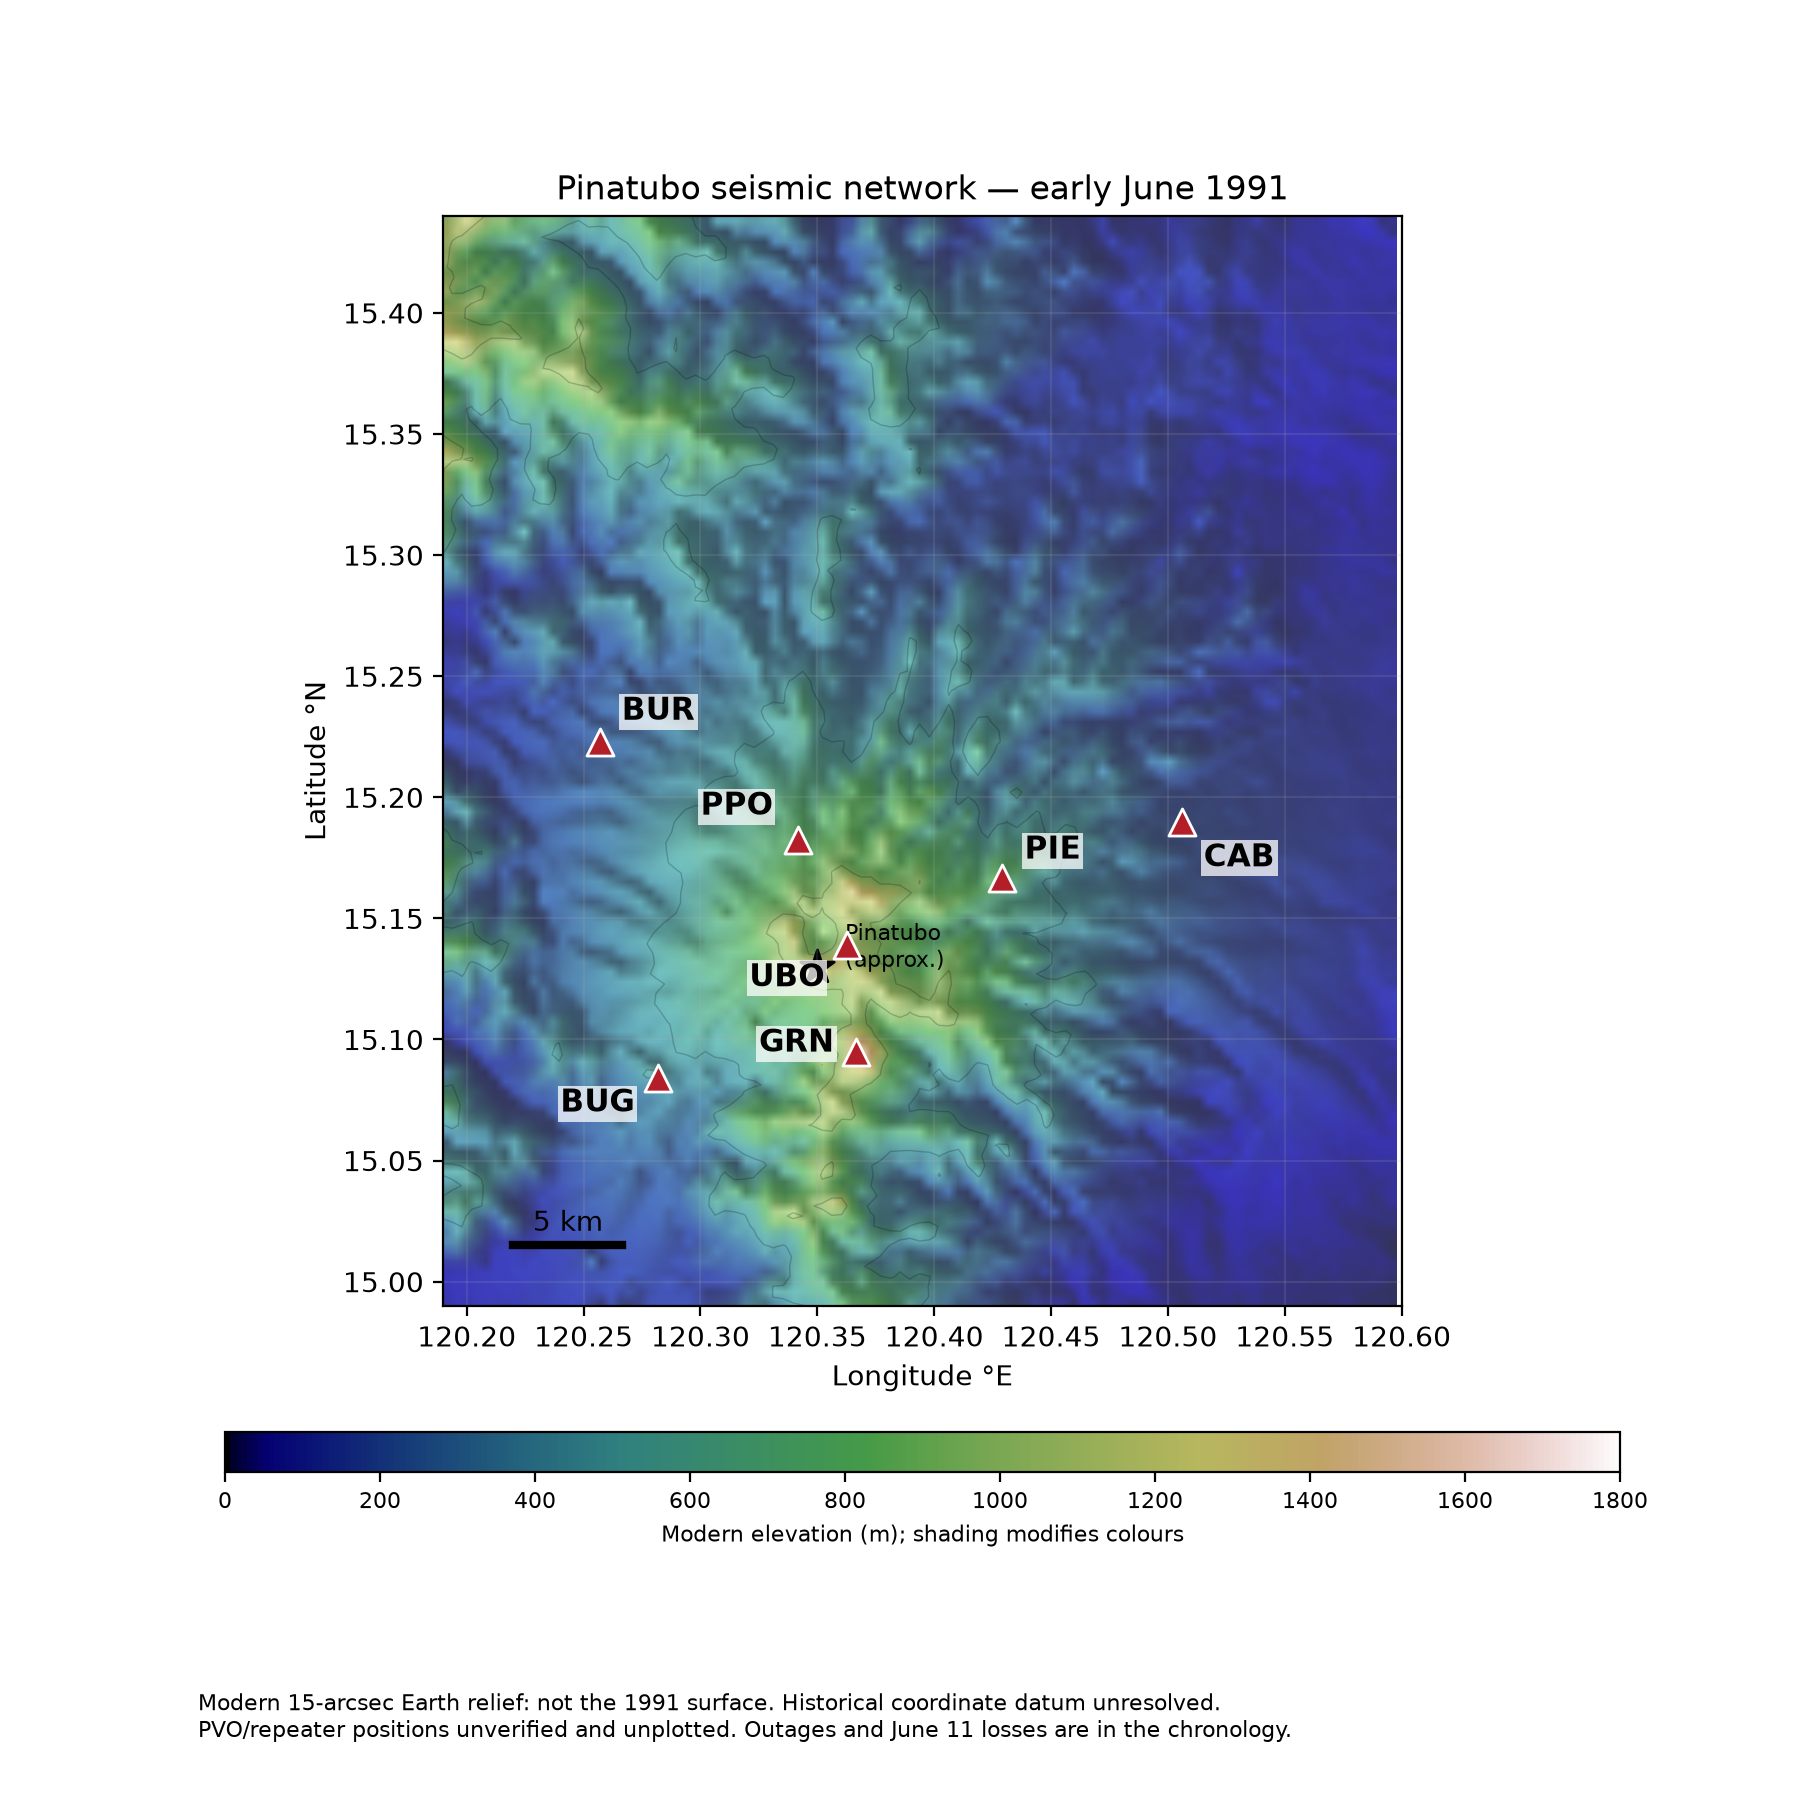

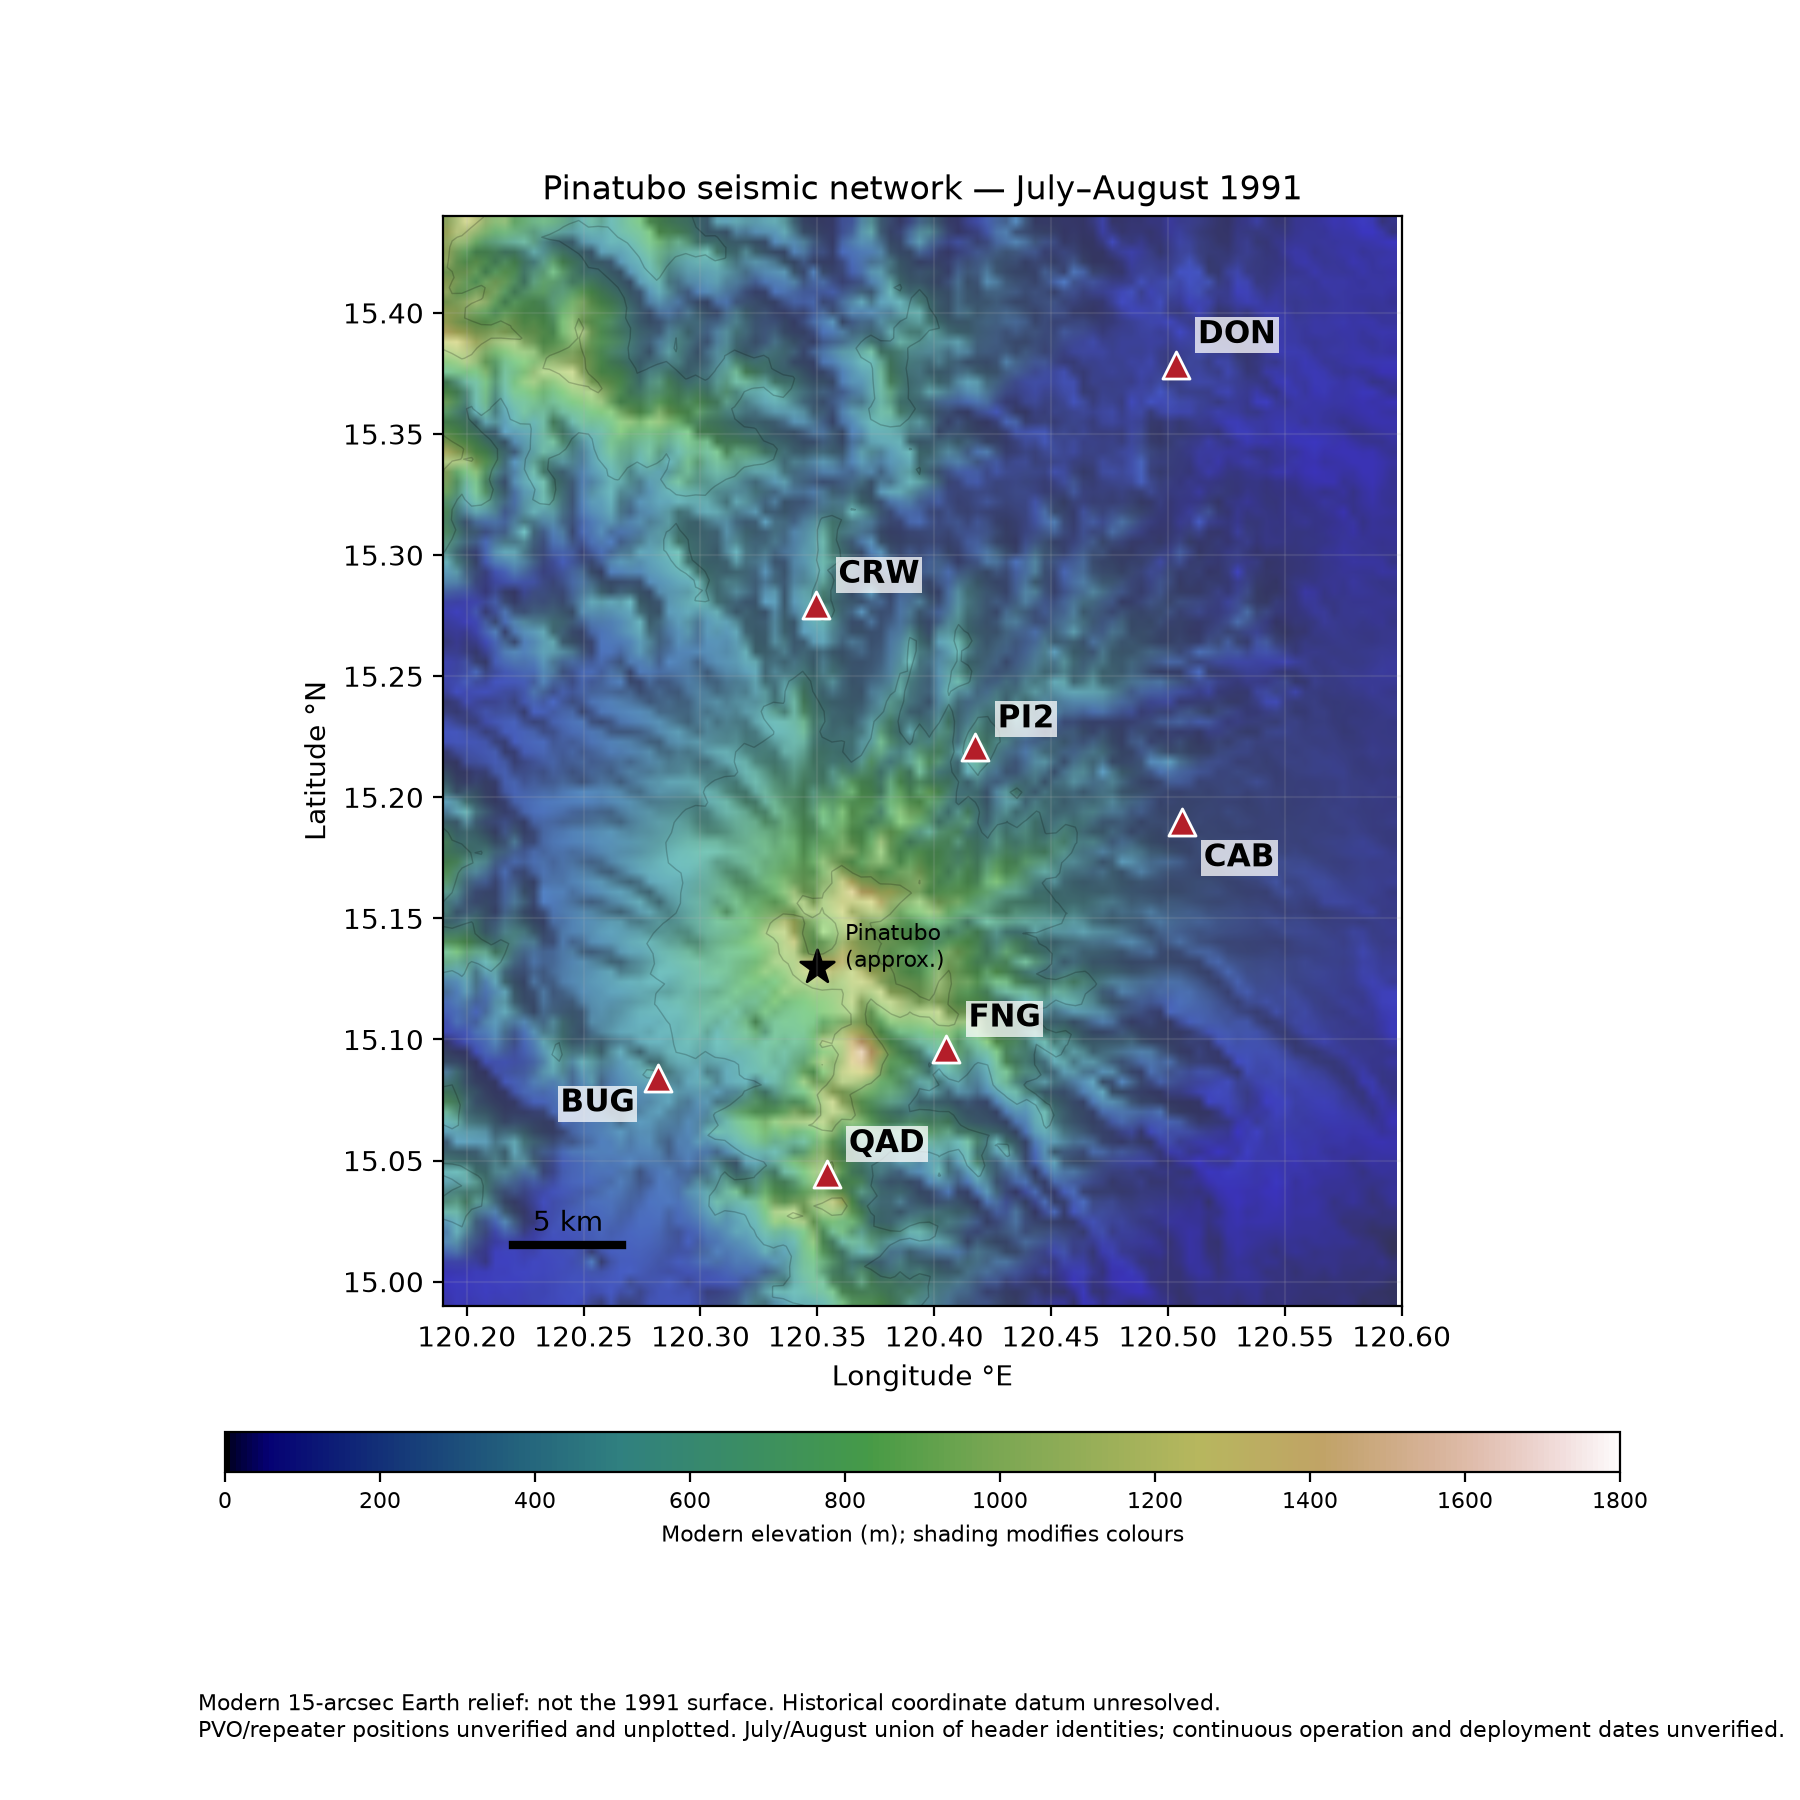

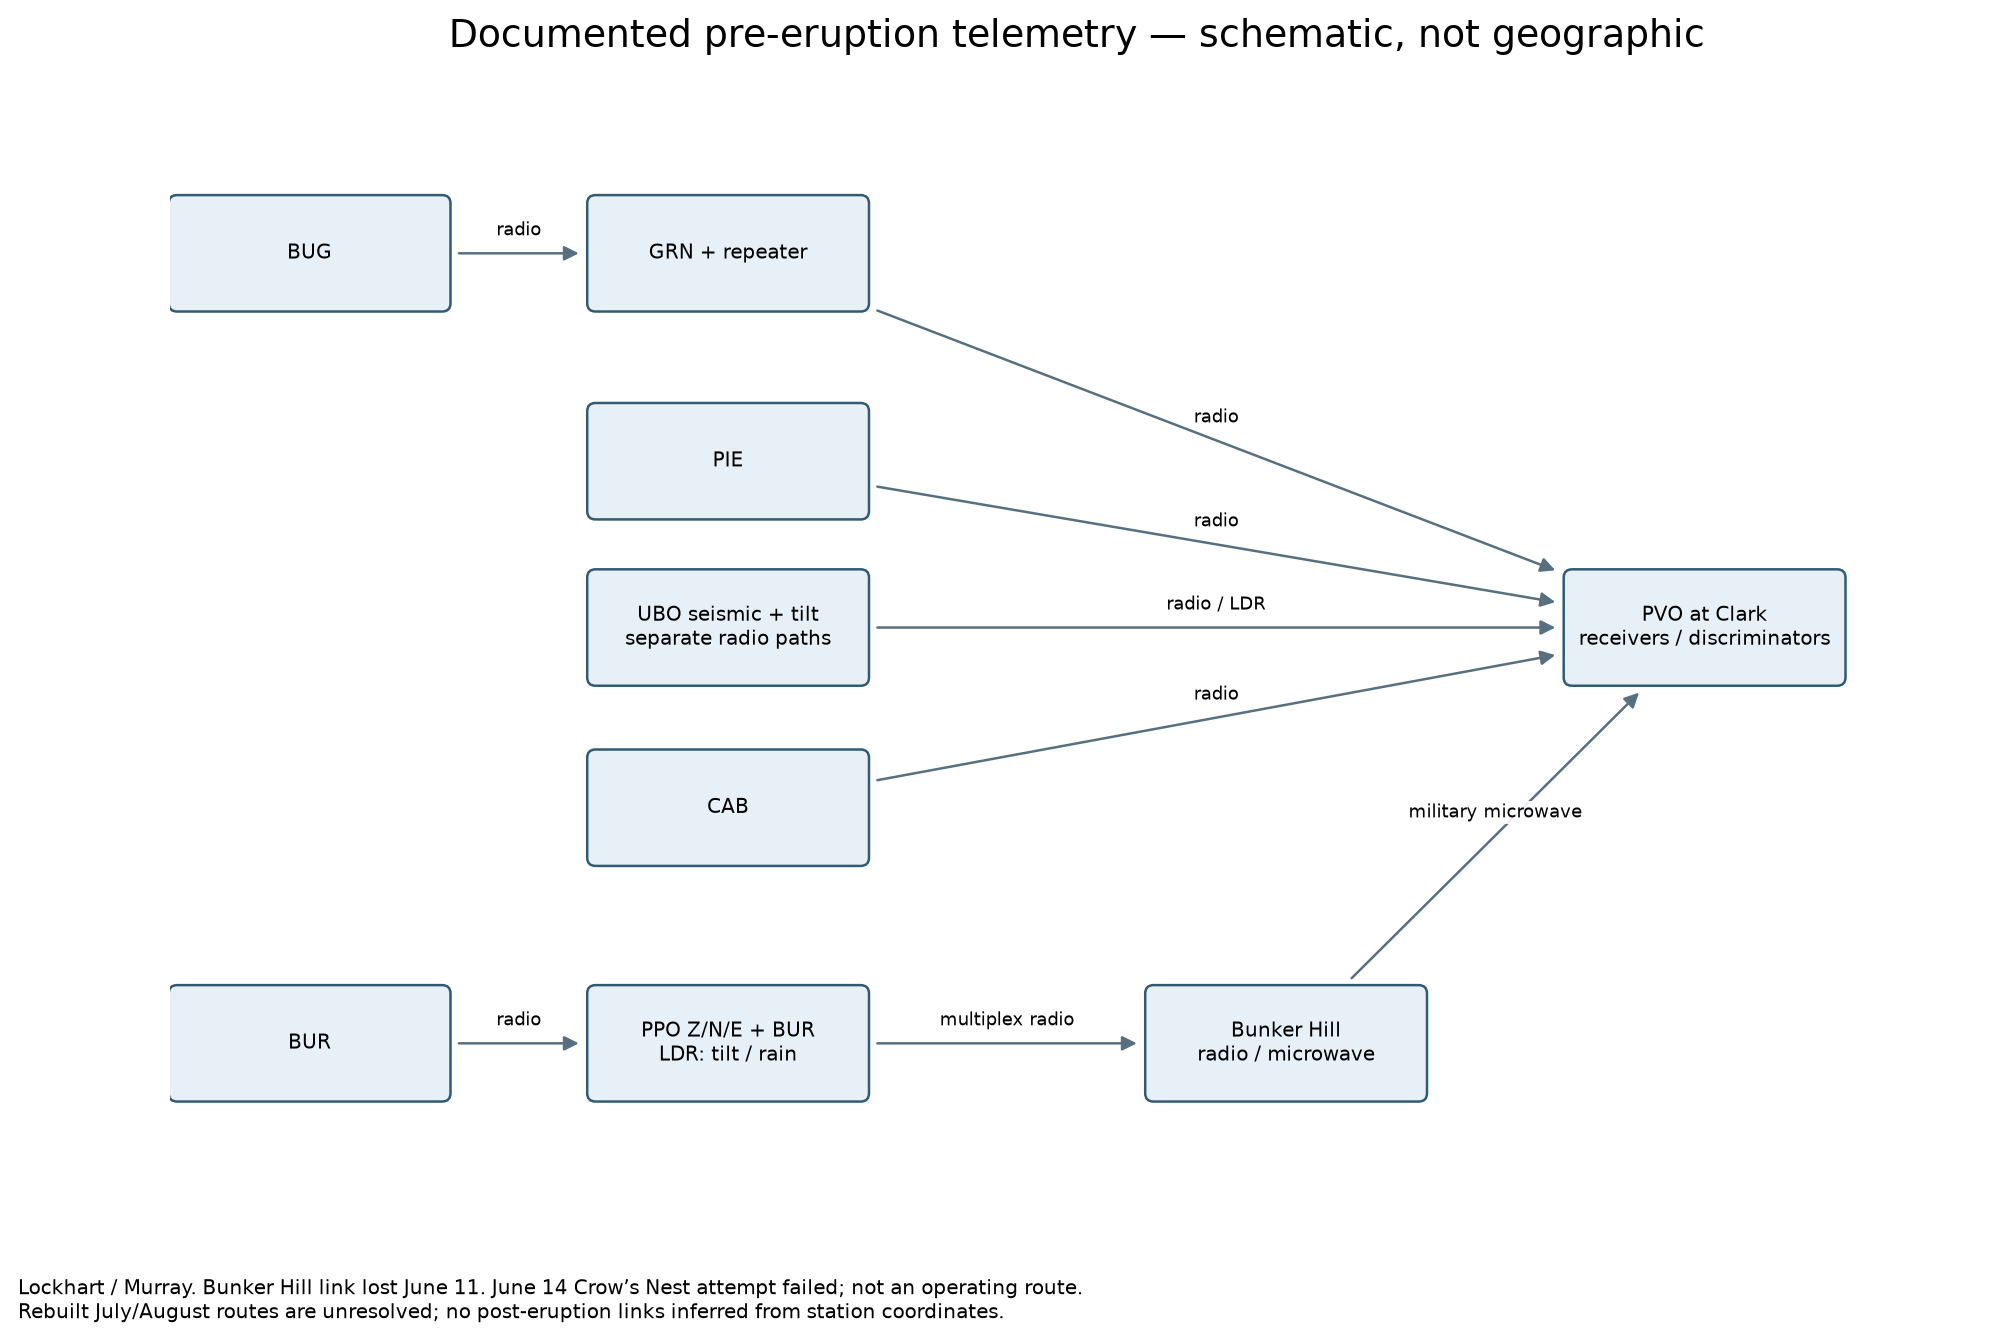

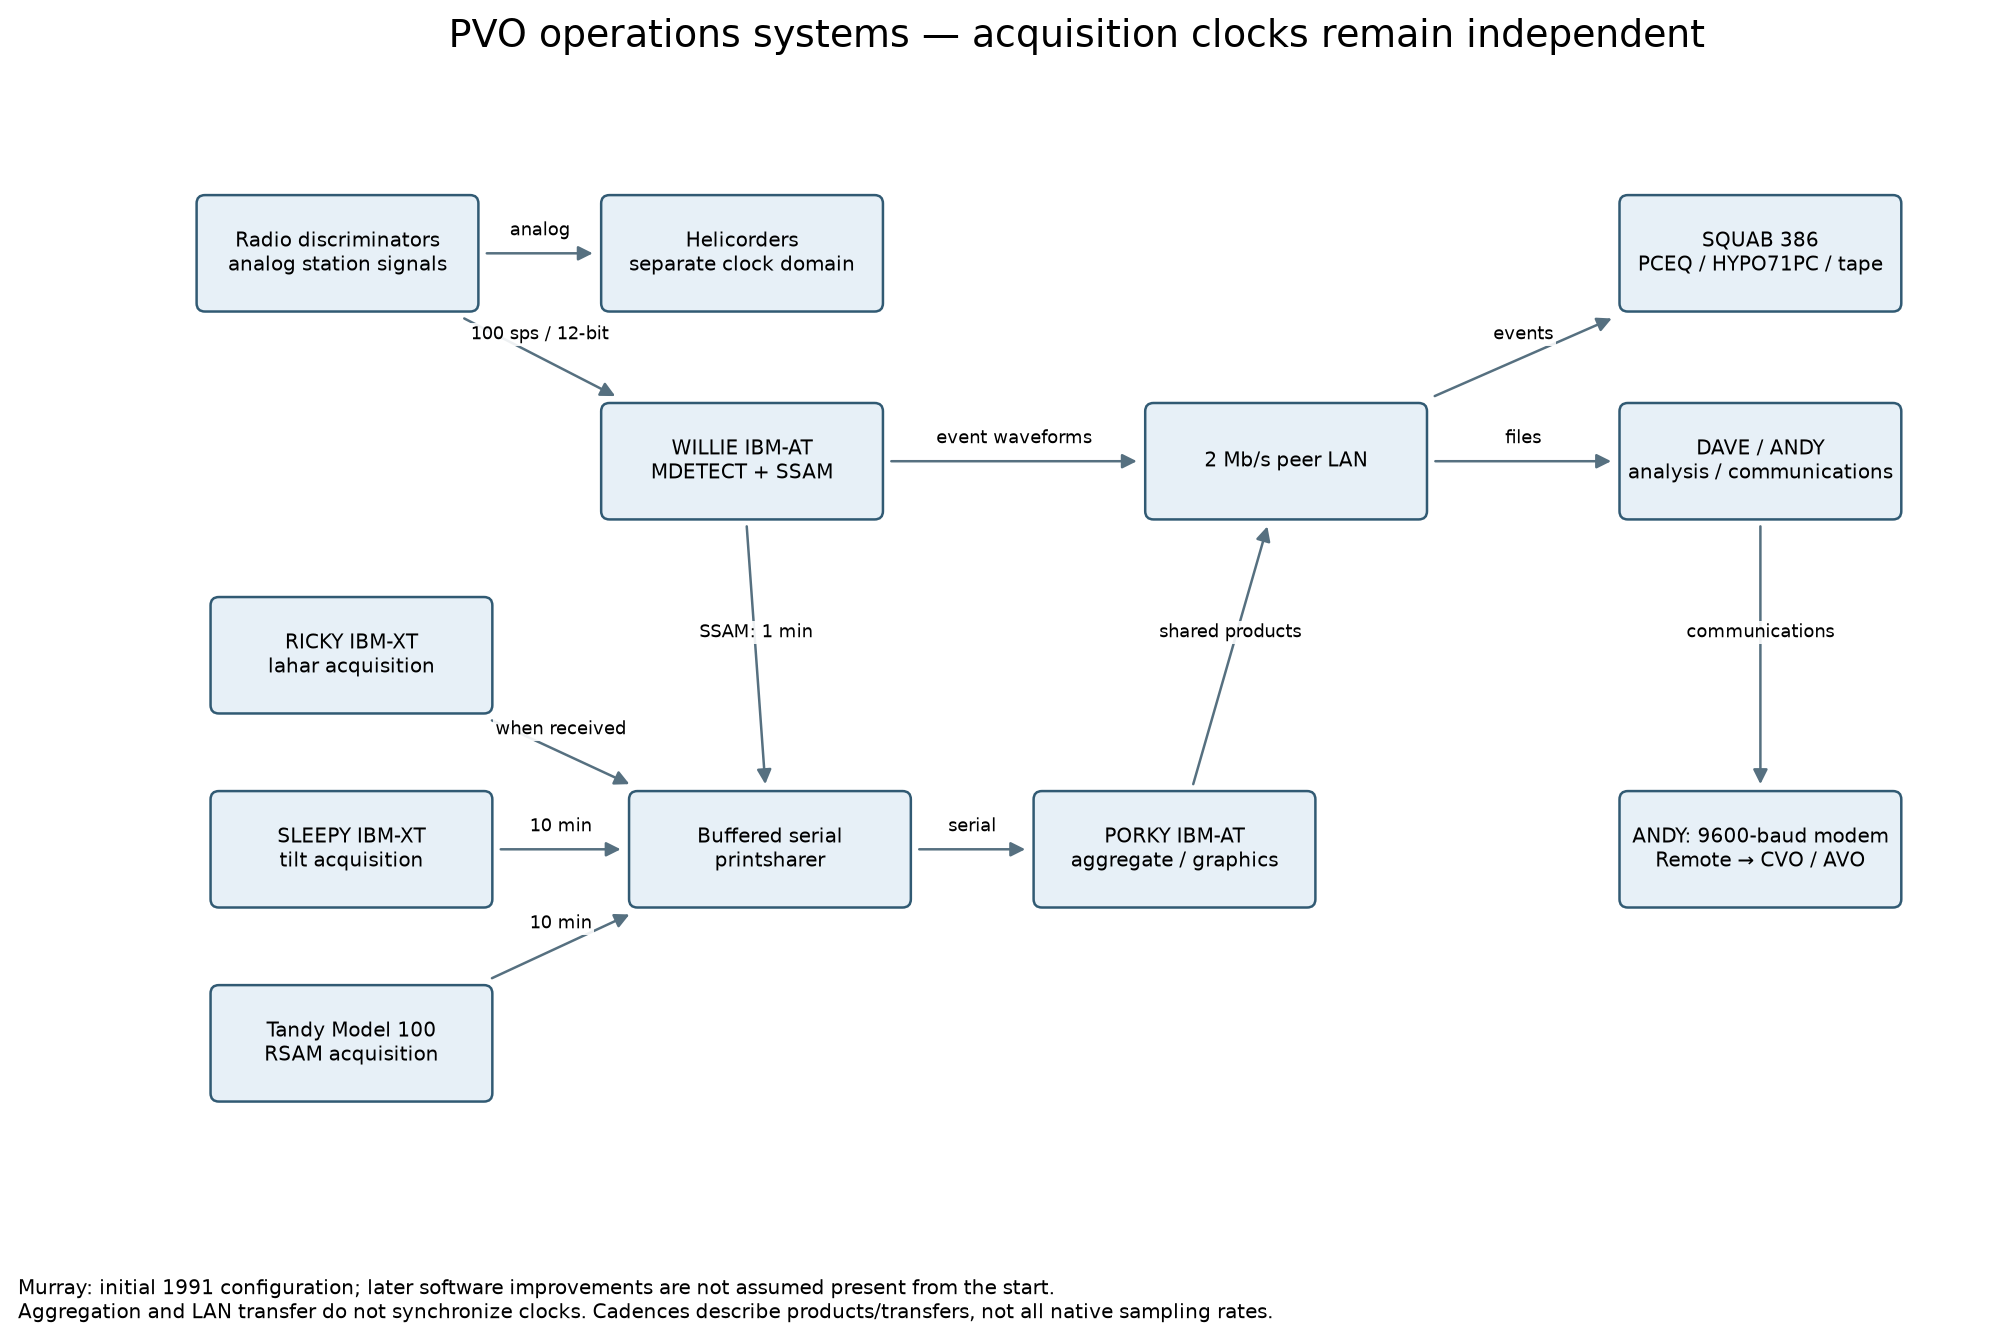

In [10]:
for name in ['network_early_june','network_july_august','telemetry','pvo_operations']:
    display(Image(filename=str(OUTPUT/(name+'.png'))))


In [11]:
provenance=package_evidence(DATA,OUTPUT,Path(P['CONFIG_FILE']),code_files=[
    PIPELINE/'network_history/reconstruct.py',PIPELINE/'network_history/finalize_inventory.py',notebook_source])
provenance.update(created_utc=datetime.now(timezone.utc).isoformat(),waveform_root=str(WAV_ROOT.resolve()),
    header_file_manifest_sha256=sha256(HEADER_OUTPUT/'waveform_file_manifest.json'),
    header_summary=json.loads((HEADER_OUTPUT/'header_scan_summary.json').read_text()),
    stationxml_audits=audits,boundary_policy='Documentary original retained; separate selection-safe copy uses 1-microsecond endpoint encoding',
    response_completeness=response_gate)
try:
    import subprocess
    provenance['git_revision']=subprocess.check_output(['git','rev-parse','HEAD'],cwd=PIPELINE,text=True).strip()
    provenance['git_dirty']=bool(subprocess.check_output(['git','status','--porcelain'],cwd=PIPELINE,text=True).strip())
except Exception as exc:provenance['git_status_unavailable']=str(exc)
provenance['step10_metadata_sha256']={key:sha256(P[key]) for key in ['WAVEFORM_INDEX','TRANSLATION_CSV'] if Path(P[key]).is_file()}
(OUTPUT/'step15_provenance.json').write_text(json.dumps(provenance,indent=2))
print('Review package:',OUTPUT)
print('Schema checks:',{name:a['schema_valid'] for name,a in audits.items()})
print('Outstanding response issues:',response_gate['missing'])


Review package: /Users/thompsong/work/Pinatubo1991Processing/converted/network_history
Schema checks: {'pinatubo_provisional.xml': True, 'pinatubo_nominal_voltage_models.xml': True}
Outstanding response issues: ['ADC counts/volt and coding', 'preamp zero-attenuation gain', 'VCO/discriminator transfer and filter assignment', 'sensor configuration/epoch conflicts']


## Completion criteria and next review

- Header failures are inspected, not silently treated as missing stations.
- Sensor conflicts and unknown coordinates/epochs remain visible.
- No unexplained positive-duration same-ID overlaps are accepted.
- Undated auxiliary/low-gain identities are not treated as verified all-time deployments.
- Response output units and missing stages are explicit.
- Original source files and raw clocks are unchanged; partial waveform recoveries require their step-10 provenance.
- The next outputs to review are waveform availability, individual/monthly picks, associations and hypocenters. These metadata products do not validate those downstream results by themselves.

**Primary references:** [Lockhart et al.](https://pubs.usgs.gov/pinatubo/lock/), [Murray et al.](https://pubs.usgs.gov/pinatubo/murray/), [Ewert et al.](https://pubs.usgs.gov/pinatubo/ewert/); additional BOB and helicorder files are identified above. Do not apply assumptions from later dual-VCO designs retrospectively to the 1991 chain.
